# Exercice 4 — Classification MNIST avec un CNN

Construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d'entraînement et 10 000 images de test, en niveaux de gris, de 28 × 28 pixels.

## 1. Chargement des données

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cuda
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Que représentent les quatre dimensions du tenseur `images` ?**
`[64, 1, 28, 28]` = `[taille du lot, canaux, hauteur, largeur]` : 64 images, 1 canal (niveaux de gris),
28 pixels de haut et 28 de large.

**Pourquoi mélanger les données d'entraînement avec `shuffle=True` ?**
Pour que chaque lot contienne un mélange de chiffres et que l'ordre change à chaque époque. Sans mélange,
le modèle verrait les exemples toujours dans le même ordre, ce qui biaise les mises à jour et peut ralentir
ou dégrader l'apprentissage. Le jeu de test n'a pas besoin d'être mélangé.

## 2. Visualiser quelques images

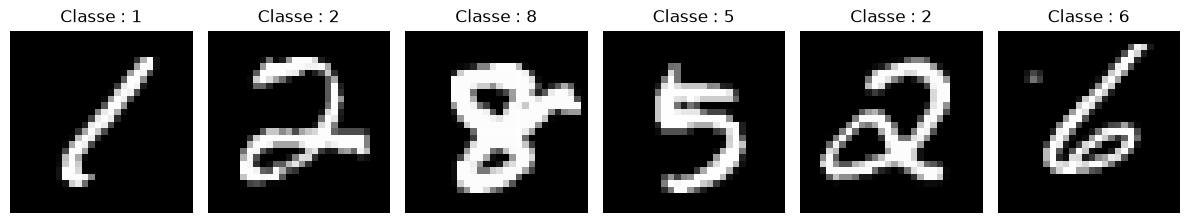

In [2]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    # Annuler la normalisation pour l'affichage
    image = images[i, 0] * 0.3081 + 0.1307

    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Construire le CNN

Architecture : deux blocs `Conv2d → ReLU → MaxPool2d` (1 → 16 puis 16 → 32 canaux), puis un classifieur
`Flatten → Linear(32×7×7, 128) → ReLU → Linear(128, 10)`.

In [3]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)

# Vérifier la forme de sortie
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)

Sortie : torch.Size([64, 10])


**Pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?**
Avec `padding=1` et un noyau 3×3, les convolutions gardent la taille de l'image. Chaque `MaxPool2d(2)` divise
la hauteur et la largeur par 2 : 28 → 14 → 7. La deuxième convolution produit 32 canaux. Avant `Flatten`, chaque
image est donc un tenseur `[32, 7, 7]`, soit **32 × 7 × 7 = 1568** valeurs.

In [4]:
x = images[:1].to(device)
print("Entrée            :", tuple(x.shape))
for couche in model.features:
    x = couche(x)
    print(f"{couche.__class__.__name__:<17} :", tuple(x.shape))

Entrée            : (1, 1, 28, 28)
Conv2d            : (1, 16, 28, 28)
ReLU              : (1, 16, 28, 28)
MaxPool2d         : (1, 16, 14, 14)
Conv2d            : (1, 32, 14, 14)
ReLU              : (1, 32, 14, 14)
MaxPool2d         : (1, 32, 7, 7)


Pas de Softmax dans le modèle : `CrossEntropyLoss` attend les scores bruts (logits).

## 4. Entraîner le réseau

In [5]:
def entrainer(model, epochs=3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # 1. Réinitialiser les gradients
            optimizer.zero_grad()

            # 2. Calculer les scores
            logits = model(images)

            # 3. Calculer la perte
            loss = criterion(logits, labels)

            # 4. Calculer les gradients
            loss.backward()

            # 5. Mettre à jour les paramètres
            optimizer.step()

            total_loss += loss.item() * images.size(0)

        average_loss = total_loss / len(train_dataset)
        loss_history.append(average_loss)
        print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")

    return loss_history

loss_history = entrainer(model, epochs=3)

Époque 1/3 | Perte : 0.1682
Époque 2/3 | Perte : 0.0485
Époque 3/3 | Perte : 0.0352


## 5. Évaluer sur le jeu de test

In [6]:
def evaluer(model):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            # Classe ayant le score le plus élevé
            predictions = logits.argmax(dim=1)

            # Compter les bonnes prédictions
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return correct / total

accuracy = evaluer(model)
print(f"Accuracy sur le test : {accuracy:.2%}")

Accuracy sur le test : 98.91%


## 6. Autres questions

### 10 images mal classées, avec leur vraie classe et la prédiction

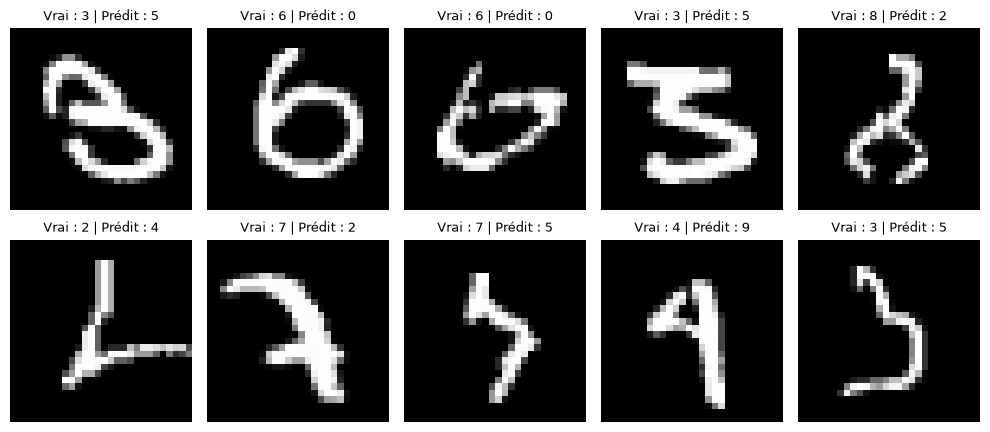

In [7]:
model.eval()
mal_classees = []

with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu()
        for image, vrai, predit in zip(images, labels, predictions):
            if vrai != predit:
                mal_classees.append((image, vrai.item(), predit.item()))
        if len(mal_classees) >= 10:
            break

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, (image, vrai, predit) in zip(axes.flat, mal_classees[:10]):
    ax.imshow(image[0] * 0.3081 + 0.1307, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai : {vrai} | Prédit : {predit}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Ajouter une couche Dropout avant la dernière couche linéaire

Le Dropout éteint aléatoirement 50 % des neurones de la couche cachée pendant l'entraînement,
ce qui limite le sur-apprentissage. Il est automatiquement désactivé par `model.eval()`.

In [8]:
class MNISTClassifierDropout(MNISTClassifier):
    def __init__(self):
        super().__init__()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )

torch.manual_seed(42)
model_dropout = MNISTClassifierDropout().to(device)
print(model_dropout.classifier)

entrainer(model_dropout, epochs=3)
accuracy_dropout = evaluer(model_dropout)
print(f"Accuracy sans Dropout : {accuracy:.2%}")
print(f"Accuracy avec Dropout : {accuracy_dropout:.2%}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=1568, out_features=128, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.5, inplace=False)
  (4): Linear(in_features=128, out_features=10, bias=True)
)
Époque 1/3 | Perte : 0.2384
Époque 2/3 | Perte : 0.0861
Époque 3/3 | Perte : 0.0659
Accuracy sans Dropout : 98.91%
Accuracy avec Dropout : 99.00%


Sur 3 époques, l'écart est faible : le Dropout ralentit un peu l'apprentissage mais améliore la généralisation
quand on entraîne plus longtemps.

### Sauvegarder les paramètres

In [9]:
torch.save(model.state_dict(), "mnist_cnn.pth")
print("Paramètres sauvegardés dans mnist_cnn.pth")

model_recharge = MNISTClassifier().to(device)
model_recharge.load_state_dict(torch.load("mnist_cnn.pth", weights_only=True))
print(f"Accuracy du modèle rechargé : {evaluer(model_recharge):.2%}")

Paramètres sauvegardés dans mnist_cnn.pth
Accuracy du modèle rechargé : 98.91%
